
ORIGINAL DATASET
  Customer  Feature_1  Feature_2
0        A          1          2
1        B          2          3
2        C          8          8
3        D          9         10
4        E          1          0
5        F          8          9

EUCLIDEAN DISTANCE MATRIX
Customer      A     B      C      D      E      F
Customer                                         
A          0.00  1.41   9.22  11.31   2.00   9.90
B          1.41  0.00   7.81   9.90   3.16   8.49
C          9.22  7.81   0.00   2.24  10.63   1.00
D         11.31  9.90   2.24   0.00  12.81   1.41
E          2.00  3.16  10.63  12.81   0.00  11.40
F          9.90  8.49   1.00   1.41  11.40   0.00

MANHATTAN DISTANCE MATRIX
Customer     A     B     C     D     E     F
Customer                                    
A          0.0   2.0  13.0  16.0   2.0  14.0
B          2.0   0.0  11.0  14.0   4.0  12.0
C         13.0  11.0   0.0   3.0  15.0   1.0
D         16.0  14.0   3.0   0.0  18.0   2.0
E          2.0   4.0  15.0 

c:\Users\Ghanavi Arun\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Ghanavi Arun\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Ghanavi Arun\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Ghanavi Arun\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executabl

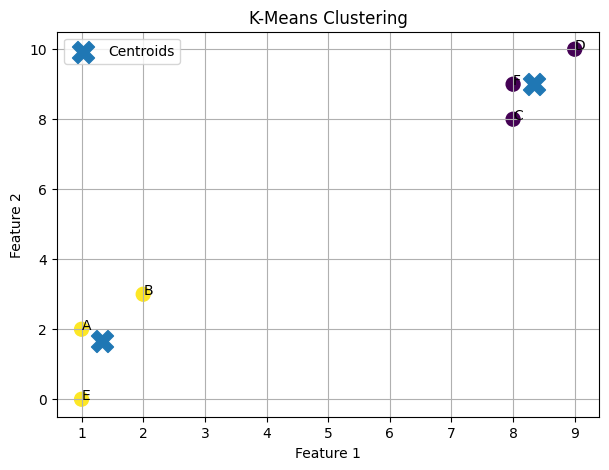

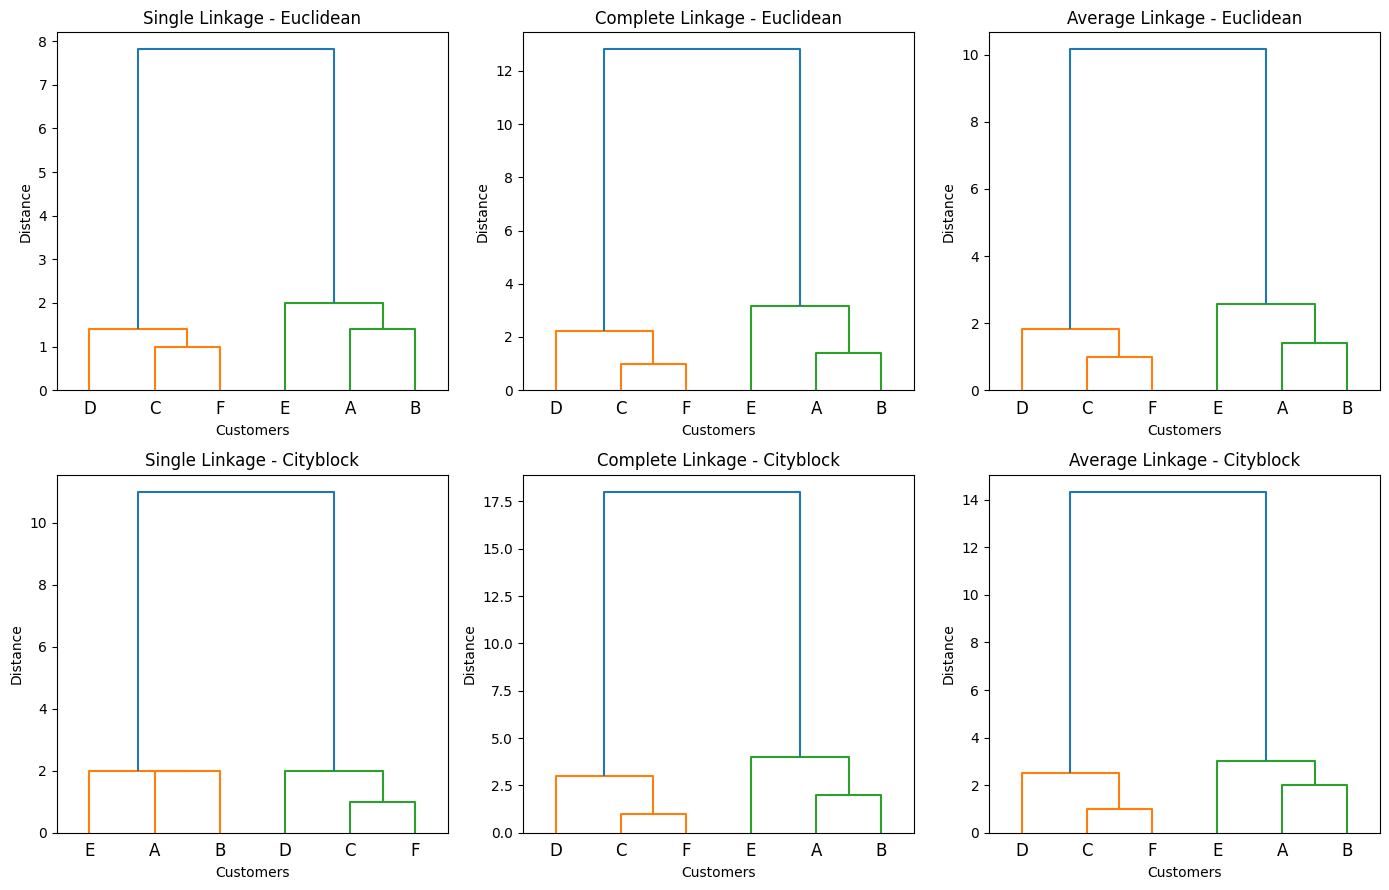

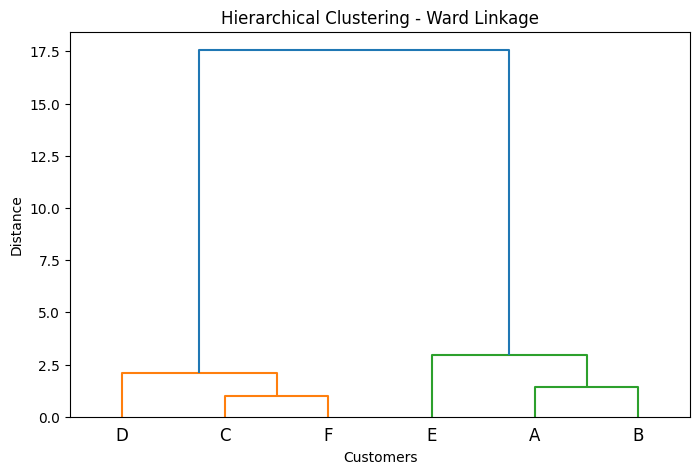


HIERARCHICAL CLUSTERING RESULTS
  Customer  Hierarchical_Cluster
0        A                     2
1        B                     2
2        C                     1
3        D                     1
4        E                     2
5        F                     1


In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans

# 1. CREATE SAMPLE DATASET
data = {
    "Customer": ["A", "B", "C", "D", "E", "F"],
    "Feature_1": [1, 2, 8, 9, 1, 8],
    "Feature_2": [2, 3, 8, 10, 0, 9]
}

df = pd.DataFrame(data)

print("\nORIGINAL DATASET")
print(df)

X = df[["Feature_1", "Feature_2"]].values

# 2. EUCLIDEAN DISTANCE
euclidean = cdist(X, X, metric="euclidean")

print("\nEUCLIDEAN DISTANCE MATRIX")
print(pd.DataFrame(
    euclidean,
    index=df["Customer"],
    columns=df["Customer"]
).round(2))

# 3. MANHATTAN DISTANCE
manhattan = cdist(X, X, metric="cityblock")

print("\nMANHATTAN DISTANCE MATRIX")
print(pd.DataFrame(
    manhattan,
    index=df["Customer"],
    columns=df["Customer"]
).round(2))

# 4. K-MEANS CLUSTERING
# K-Means uses Euclidean-distance-based clustering
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

df["KMeans_Cluster"] = kmeans.fit_predict(X)

print("\nK-MEANS CLUSTERING RESULTS")
print(df)

print("\nCLUSTER CENTROIDS")
print(kmeans.cluster_centers_)

# Visualize K-Means clusters
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=df["KMeans_Cluster"],
    s=100
)

# Display customer names
for i, name in enumerate(df["Customer"]):
    plt.annotate(name, (X[i, 0], X[i, 1]))

# Display centroids
centres = kmeans.cluster_centers_

plt.scatter(
    centres[:, 0],
    centres[:, 1],
    marker="X",
    s=250,
    label="Centroids"
)

plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid()
plt.show()

# ------------------------------------------------
# 5. HIERARCHICAL CLUSTERING
# ------------------------------------------------
# Compare different linkage methods
methods = ["single", "complete", "average"]
metrics = ["euclidean", "cityblock"]

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for i, metric in enumerate(metrics):
    for j, method in enumerate(methods):
        Z = linkage(X, method=method, metric=metric)

        dendrogram(
            Z,
            labels=df["Customer"].values,
            ax=axes[i, j]
        )

        axes[i, j].set_title(
            f"{method.capitalize()} Linkage - {metric.capitalize()}"
        )

        axes[i, j].set_xlabel("Customers")
        axes[i, j].set_ylabel("Distance")

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 6. WARD LINKAGE (EUCLIDEAN ONLY)
# ------------------------------------------------
Z_ward = linkage(X, method="ward", metric="euclidean")

plt.figure(figsize=(8, 5))

dendrogram(
    Z_ward,
    labels=df["Customer"].values
)

plt.title("Hierarchical Clustering - Ward Linkage")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()

# ------------------------------------------------
# 7. HIERARCHICAL CLUSTER ASSIGNMENTS
# ------------------------------------------------
# Euclidean distance with Ward linkage
df["Hierarchical_Cluster"] = fcluster(
    Z_ward,
    t=2,
    criterion="maxclust"
)

print("\nHIERARCHICAL CLUSTERING RESULTS")
print(df[["Customer", "Hierarchical_Cluster"]])